# 01 · Gares de voyageurs d'Auvergne-Rhône-Alpes

**Objectif** : obtenir la liste propre des gares de voyageurs de la région, avec leur position et leur fréquentation, pour évaluer l'intérêt d'une station Citiz à proximité (rabattement train + autopartage).

**Sources** (SNCF Open Data, licence ODbL) :

- `gares-de-voyageurs` : une ligne par gare, avec sa position, son code INSEE de commune, ses codes UIC et son **segment DRG** ;
- `frequentation-gares` : nombre annuel de voyageurs par gare, de 2015 à 2024, identifié par le code UIC.

Le **code UIC** est l'identifiant international d'une gare (8 chiffres, `87` pour la France). C'est la clé de jointure entre les deux fichiers.

Le **segment DRG** est la classification SNCF Gares & Connexions : `A` gare nationale (plus de 250 000 voyageurs par an et une part importante de voyageurs grandes lignes), `B` gare régionale (plus de 100 000 voyageurs par an), `C` gare locale.

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (d / "siting-data" / "siting_sources.py").is_file())
sys.path.insert(0, str(ROOT / "siting-data"))
from siting_sources import AURA_DEPARTMENTS, download, load_departments, load_region, module_paths

ROOT, RAW, CLEAN = module_paths()
SNCF_EXPORT = "https://ressources.data.sncf.com/api/explore/v2.1/catalog/datasets/{}/exports/csv"
print("Project root:", ROOT)

Project root: /home/tfeat/Epitech/msc-1/Hackathon


## 1. Téléchargement

Les fichiers sont téléchargés une seule fois dans `data/raw/` ; les exécutions suivantes réutilisent la copie locale. L'URL, la date et l'empreinte SHA-256 de chaque fichier sont consignées dans `data/raw/download_manifest.json`. Pour récupérer une version plus récente, passer `refresh=True`.

In [2]:
stations_path = download(SNCF_EXPORT.format("gares-de-voyageurs"), RAW / "sncf_gares_de_voyageurs.csv",
                         params={"delimiter": ";"}, description="SNCF gares de voyageurs")
ridership_path = download(SNCF_EXPORT.format("frequentation-gares"), RAW / "sncf_frequentation_gares.csv",
                          params={"delimiter": ";"}, description="SNCF fréquentation en gares")

stations_raw = pd.read_csv(stations_path, sep=";", dtype=str)
ridership_raw = pd.read_csv(ridership_path, sep=";", dtype=str)
print(f"Stations (France): {len(stations_raw)} rows, ridership: {len(ridership_raw)} rows")
stations_raw.head(3)

Stations (France): 2792 rows, ridership: 3021 rows


,nom,libellecourt,segment_drg,position_geographique,codeinsee,codes_uic,id
0,Abancourt,ABT,C,"49.6852237, 1.7743058",60001,87313759,a99c4503-7fa0-4176-b908-74f5e50cba32
1,Abbaretz,AAR,C,"47.5546432, -1.5244159",44001,87481614,5fe4e77c-2519-413d-a242-4a525e656a09
2,Abbeville,ABB,B,"50.10221, 1.82449",80001,87317362,c4a3e70f-d42c-4026-98e6-35089225688a


## 2. Filtrer la région

Le code INSEE de commune commence par le code du département : on garde les 12 départements d'Auvergne-Rhône-Alpes. On vérifie ensuite que chaque gare retenue est bien **dans le contour IGN** de la région (fichier versionné par `regional-data/`), pour détecter une éventuelle erreur de code ou de position.

La position est fournie sous forme de texte `"latitude, longitude"` : on la découpe en deux nombres.

In [3]:
stations = stations_raw.copy()
stations["department_code"] = stations["codeinsee"].str[:2]
stations = stations.loc[stations["department_code"].isin(AURA_DEPARTMENTS)].copy()

coordinates = stations["position_geographique"].str.split(",", expand=True).astype(float)
stations["lat"], stations["lon"] = coordinates[0], coordinates[1]

region = load_region()
points = gpd.GeoSeries(gpd.points_from_xy(stations["lon"], stations["lat"]), crs=4326, index=stations.index)
stations["inside_region"] = points.within(region)
print(f"{len(stations)} stations in AURA departments; outside IGN outline: {(~stations['inside_region']).sum()}")
stations.loc[~stations["inside_region"], ["nom", "codeinsee", "lat", "lon"]]

329 stations in AURA departments; outside IGN outline: 0


,nom,codeinsee,lat,lon


## 3. Contrôles de qualité

On vérifie les identifiants, les valeurs manquantes et les codes inhabituels avant de nettoyer :

- une gare peut avoir **plusieurs codes UIC** séparés par `;` ;
- un segment DRG peut être **double** (`B;C`) quand la gare regroupe plusieurs entités.

In [4]:
checks = {
    "rows": len(stations),
    "unique SNCF id": stations["id"].is_unique,
    "missing coordinates": int(stations[["lat", "lon"]].isna().any(axis=1).sum()),
    "missing UIC code": int(stations["codes_uic"].isna().sum()),
    "several UIC codes": int(stations["codes_uic"].str.contains(";").sum()),
    "duplicated names": int(stations["nom"].duplicated().sum()),
}
display(pd.Series(checks, name="value").to_frame())
display(stations["segment_drg"].value_counts(dropna=False).rename("stations").to_frame())
stations.loc[stations["codes_uic"].str.contains(";") | stations["segment_drg"].str.contains(";"),
             ["nom", "codes_uic", "segment_drg"]]

,value
rows,329
unique SNCF id,True
missing coordinates,0
missing UIC code,0
several UIC codes,1
duplicated names,0


,stations
segment_drg,
C,181
B,132
A,15
B;C,1


,nom,codes_uic,segment_drg
2247,Saint-Gervais-les-Bains Le Fayet,87746479;87744078,B;C


## 4. Joindre la fréquentation

On découpe la liste des codes UIC (une ligne par code), on joint la fréquentation, puis on **additionne** les voyageurs des codes d'une même gare. Une gare sans fréquentation publiée garde une valeur **vide** : ce n'est pas une gare sans voyageurs.

On conserve 2024 (dernière année), 2023 et 2019 (dernière année avant la crise sanitaire), en voyageurs hors non-voyageurs : les « non-voyageurs » sont les personnes qui traversent la gare sans prendre le train.

In [5]:
YEARS = ["2024", "2023", "2019"]
ridership = ridership_raw.rename(columns={"code_uic_complet": "uic_code"})
ridership = ridership[["uic_code", "segmentation_marketing", *[f"total_voyageurs_{y}" for y in YEARS]]]
for year in YEARS:
    ridership[f"total_voyageurs_{year}"] = pd.to_numeric(ridership[f"total_voyageurs_{year}"], errors="coerce")
assert ridership["uic_code"].is_unique

codes = stations[["id", "codes_uic"]].assign(uic_code=stations["codes_uic"].str.split(";")).explode("uic_code")
codes["uic_code"] = codes["uic_code"].str.strip()
joined = codes.merge(ridership, on="uic_code", how="left")
per_station = joined.groupby("id").agg(
    uic_codes_matched=("total_voyageurs_2024", "count"),
    marketing_segment=("segmentation_marketing", lambda v: ";".join(sorted(set(v.dropna())))),
    **{f"passengers_{y}": (f"total_voyageurs_{y}", lambda v: v.sum(min_count=1)) for y in YEARS},
)
stations = stations.merge(per_station, left_on="id", right_index=True, how="left")
print(f"Stations with 2024 ridership: {stations['passengers_2024'].notna().sum()} / {len(stations)}")
stations.loc[stations["passengers_2024"].isna(), ["nom", "codes_uic", "segment_drg"]]

Stations with 2024 ridership: 329 / 329


,nom,codes_uic,segment_drg


## 5. Rattacher le département et construire la table propre

Le nom du département vient des contours simplifiés IGN déjà utilisés par le module `citiz/`. Les colonnes sont renommées en anglais, comme dans le reste du dépôt ; `station_uid` suit la convention `source:identifiant`.

In [6]:
departments = load_departments()[["department_code", "department_name"]]
train_stations = (
    stations.merge(departments, on="department_code", how="left")
    .assign(
        station_uid=lambda t: "sncf:" + t["id"],
        uic_code=lambda t: t["codes_uic"].str.split(";").str[0],
        source="SNCF gares-de-voyageurs + frequentation-gares",
    )
    .rename(columns={"nom": "name", "libellecourt": "short_code", "codeinsee": "insee_code",
                     "codes_uic": "uic_codes"})
)
COLUMNS = ["station_uid", "uic_code", "uic_codes", "name", "short_code", "insee_code", "department_code",
           "department_name", "segment_drg", "marketing_segment", "passengers_2024", "passengers_2023",
           "passengers_2019", "uic_codes_matched", "lon", "lat", "inside_region", "source"]
train_stations = train_stations[COLUMNS].sort_values(["department_code", "name"]).reset_index(drop=True)
for column in ["passengers_2024", "passengers_2023", "passengers_2019"]:
    train_stations[column] = train_stations[column].astype("Int64")
train_stations.head()

,station_uid,uic_code,uic_codes,name,short_code,insee_code,department_code,department_name,segment_drg,marketing_segment,passengers_2024,passengers_2023,passengers_2019,uic_codes_matched,lon,lat,inside_region,source
0,sncf:39a85828-0e36-4d89-bc45-242c8696ce4c,87743146,87743146,Ambronay - Priay,AAI,01007,01,Ain,C,Halte,8293,8222,9145,1,5.338258,46.011594,True,SNCF gares-de-voyageurs + frequentation-gares
1,sncf:dd738eff-6705-4a38-aa3e-4b61045b8d78,87743716,87743716,Ambérieu-en-Bugey,AMB,01004,01,Ain,B,Ville,1527121,1404224,1254920,1,5.342388,45.954008,True,SNCF gares-de-voyageurs + frequentation-gares
2,sncf:88ab44f6-65e0-4524-98d3-7d18d06b8b69,87745000,87745000,Bellegarde-sur-Valserine,BGD,01033,01,Ain,A,Ville,1769256,1723382,1305663,1,5.823483,46.109425,True,SNCF gares-de-voyageurs + frequentation-gares
3,sncf:d86d00f6-c44e-47d8-ad7f-49bc8a1b8d6e,87743526,87743526,Bellignat,BNI,01031,01,Ain,C,Halte,4083,5116,5373,1,5.629885,46.238126,True,SNCF gares-de-voyageurs + frequentation-gares
4,sncf:f5afd795-d3c8-4407-abd0-cbacb3c0bb0c,87723544,87723544,Beynost,BNO,01043,01,Ain,B,Halte,294449,267635,213302,1,5.006969,45.833915,True,SNCF gares-de-voyageurs + frequentation-gares


## 6. Chiffres clés et carte

In [7]:
summary = train_stations.groupby(["department_code", "department_name"]).agg(
    stations=("station_uid", "size"),
    segment_A=("segment_drg", lambda s: (s == "A").sum()),
    segment_B=("segment_drg", lambda s: s.str.startswith("B").sum()),
    segment_C=("segment_drg", lambda s: (s == "C").sum()),
    passengers_2024=("passengers_2024", "sum"),
)
display(summary)
train_stations.nlargest(10, "passengers_2024")[["name", "department_code", "segment_drg", "passengers_2024"]]

,,stations,segment_A,segment_B,segment_C,passengers_2024
department_code,department_name,,,,,
01,Ain,38,2,14,22,10521555
03,Allier,19,2,4,13,3217863
07,Ardèche,1,0,0,1,752
15,Cantal,14,0,1,13,362598
26,Drôme,16,3,5,8,10049017
38,Isère,42,1,28,13,27468102
42,Loire,28,1,10,17,8786837
43,Haute-Loire,18,0,3,15,897824
63,Puy-de-Dôme,26,1,8,17,8978990


,name,department_code,segment_drg,passengers_2024
241,Lyon Part Dieu,69,A,42434779
96,Grenoble,38,A,8776384
242,Lyon Perrache,69,A,7871334
270,Chambéry - Challes-les-Eaux,73,A,5105918
182,Clermont-Ferrand,63,A,4922516
153,Saint-Étienne Châteaucreux,42,A,4203481
87,Valence TGV Rhône-Alpes Sud,26,A,3283288
290,Annecy,74,A,3202251
86,Valence,26,A,2917986
261,Villefranche-sur-Saône,69,B,2829718


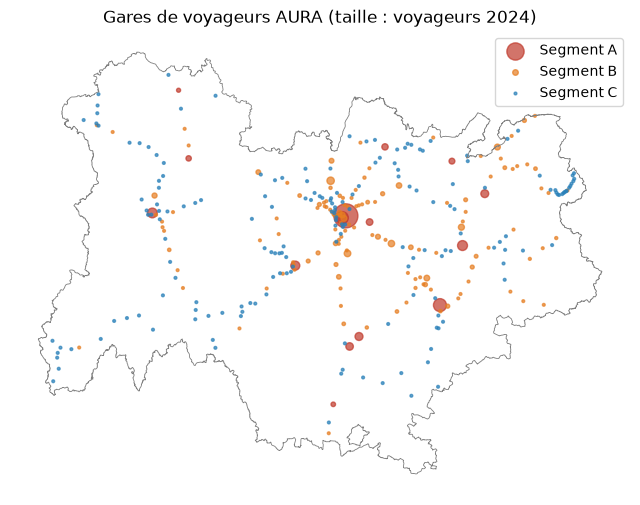

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
gpd.GeoSeries([region], crs=4326).boundary.plot(ax=ax, color="grey", linewidth=0.6)
colors = {"A": "#c0392b", "B": "#e67e22", "C": "#2980b9"}
for segment, group in train_stations.groupby(train_stations["segment_drg"].str[0]):
    size = (group["passengers_2024"].fillna(0) / 1e5).clip(lower=4, upper=300)
    ax.scatter(group["lon"], group["lat"], s=size, color=colors[segment], alpha=0.7, label=f"Segment {segment}")
ax.set_title("Gares de voyageurs AURA (taille : voyageurs 2024)")
ax.legend()
ax.set_axis_off()
plt.show()

## 7. Export et relecture

Le CSV est écrit en UTF-8, séparateur virgule, cellules inconnues vides. On le relit pour vérifier qu'il est identique à la table en mémoire.

In [9]:
output_path = CLEAN / "train_stations_aura.csv"
train_stations.to_csv(output_path, index=False)

reread = pd.read_csv(output_path, dtype={"uic_code": str, "uic_codes": str, "insee_code": str,
                                         "department_code": str})
assert len(reread) == len(train_stations)
assert reread["station_uid"].is_unique
assert reread["lon"].between(2, 8).all() and reread["lat"].between(44, 47).all()
assert reread["passengers_2024"].isna().sum() == train_stations["passengers_2024"].isna().sum()
print(f"Wrote {output_path.relative_to(ROOT)}: {len(reread)} stations, {reread.shape[1]} columns")

Wrote siting-data/data/clean/train_stations_aura.csv: 329 stations, 18 columns
